# 🔬 Colonic Polyp Detection — Optimised Kaggle Edition
## YOLOv8n + Faster R-CNN (ResNet50-FPN) + WBF + ByteTrack

---

### ⚙️ One-Time Kaggle Setup (do before running)
1. **GPU** → Notebook Settings → Accelerator → **GPU P100**
2. **Internet** → Settings → Internet → **On**
3. **Add datasets** via the Add Data button:
   - `awsaf49/kvasir-seg`
   - `balraj98/cvcclinicdb`

### ⚡ Optimisations vs original
| Setting | Original | This version |
|---|---|---|
| Image size | 640 | **416** (-58% VRAM) |
| YOLO model | yolov8s | **yolov8n** |
| YOLO epochs | 80 | **40** + early stop |
| FRCNN epochs | 25 | **15** |
| K-Folds | 5 | **3** |
| Batch YOLO | 16 | **8** |
| Batch FRCNN | 6 | **2** + grad_accum=4 |
| Backbone | ResNet50-FPN | **ResNet50-FPN** (kept) |

### 🔁 Checkpoint System
Checkpoints saved to `/kaggle/working/` after every stage and every fold.
If session times out → **re-run all cells from top** → completed stages are skipped.

```python
reset_checkpoint('stage_name')  # re-run one stage
reset_checkpoint()              # start completely fresh
```

In [1]:
# ============================================================
# CELL 0.1 — GPU check
# ============================================================
import subprocess, torch

print('='*55)
print('  RUNTIME ENVIRONMENT CHECK')
print('='*55)

gpu_ok  = torch.cuda.is_available()
print(f'  GPU Available : {gpu_ok}')
if gpu_ok:
    vram_gb = torch.cuda.get_device_properties(0).total_memory / 1e9
    print(f'  GPU Name      : {torch.cuda.get_device_name(0)}')
    print(f'  CUDA          : {torch.version.cuda}')
    print(f'  VRAM          : {vram_gb:.1f} GB')
    if vram_gb < 10:
        print('  ⚠ Low VRAM — if OOM, reduce BATCH_FRCNN to 1')
else:
    print('  ⚠ No GPU! Settings → Accelerator → GPU P100')

print(f'  PyTorch       : {torch.__version__}')
print(f'  Python        : {subprocess.check_output(["python","--version"]).decode().strip()}')
print('='*55)
DEVICE = 'cuda' if gpu_ok else 'cpu'
print(f'  Using device  : {DEVICE}')

  RUNTIME ENVIRONMENT CHECK
  GPU Available : True
  GPU Name      : Tesla T4
  CUDA          : 12.8
  VRAM          : 15.6 GB
  PyTorch       : 2.10.0+cu128
  Python        : Python 3.12.12
  Using device  : cuda


In [2]:
# ============================================================
# CELL 1.1 — Install packages
# Kaggle already has torch/torchvision/cv2 pre-installed
# ============================================================
import subprocess, sys

packages = ['ultralytics', 'ensemble-boxes', 'supervision', 'pycocotools']
print('Installing packages...')
for pkg in packages:
    r = subprocess.run([sys.executable,'-m','pip','install',pkg,'-q'],
                       capture_output=True, text=True)
    print(f'  {"✓" if r.returncode==0 else "✗"} {pkg}')
print('Done!')

Installing packages...
  ✓ ultralytics
  ✓ ensemble-boxes
  ✓ supervision
  ✓ pycocotools
Done!


In [3]:
# ============================================================
# CELL 1.2 — Imports and global config
# KAGGLE: paths use /kaggle/working/ and /kaggle/input/
# OPT: IMG_SIZE=416, K_FOLDS=3, reduced epochs+batches,
#      GRAD_ACCUM=4 to simulate larger effective batch size
# ============================================================
import os, sys, cv2, json, time, random, shutil, warnings
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from tqdm import tqdm
from collections import defaultdict
from sklearn.model_selection import KFold
from concurrent.futures import ThreadPoolExecutor
import threading, queue

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models.detection import (
    fasterrcnn_resnet50_fpn, FasterRCNN_ResNet50_FPN_Weights
)
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.ops import box_iou
from torch.cuda.amp import GradScaler, autocast

from ultralytics import YOLO
from ensemble_boxes import weighted_boxes_fusion
import supervision as sv

warnings.filterwarnings('ignore')

# ── GLOBAL CONFIG ──────────────────────────────────────────
DEVICE       = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
IMG_SIZE     = 416      # was 640 — cuts VRAM ~58%
K_FOLDS      = 3        # was 5
YOLO_EPOCHS  = 40       # was 80 (+ early stop patience=10)
FRCNN_EPOCHS = 15       # was 25
BATCH_YOLO   = 8        # was 16
BATCH_FRCNN  = 2        # was 6 — safe for ResNet50 on P100
GRAD_ACCUM   = 4        # effective FRCNN batch = 2*4 = 8
NUM_WORKERS  = 2        # kaggle has 2 CPUs reliably
SEED         = 42

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = True  # faster fixed-size convolutions

# ── KAGGLE PATHS ───────────────────────────────────────────
WORKING_DIR = Path('/kaggle/working')
BASE_DIR    = WORKING_DIR / 'polyp_project'
RAW_DIR     = BASE_DIR / 'raw_data'
DATASET_DIR = BASE_DIR / 'dataset'
RUNS_DIR    = BASE_DIR / 'runs'
OUTPUT_DIR  = BASE_DIR / 'outputs'
# Checkpoint lives at /kaggle/working root — persists between sessions
CKPT_FILE   = WORKING_DIR / 'pipeline_checkpoint.json'

for d in [BASE_DIR, RAW_DIR, DATASET_DIR, RUNS_DIR, OUTPUT_DIR]:
    d.mkdir(parents=True, exist_ok=True)

print(f'Device      : {DEVICE}')
print(f'Working dir : {WORKING_DIR}')
print(f'IMG_SIZE    : {IMG_SIZE}')
print(f'K_FOLDS     : {K_FOLDS}')
print(f'YOLO epochs : {YOLO_EPOCHS} (patience=10 early stop)')
print(f'FRCNN epochs: {FRCNN_EPOCHS}')
print(f'Batch YOLO  : {BATCH_YOLO}')
print(f'Batch FRCNN : {BATCH_FRCNN} × {GRAD_ACCUM} accum = {BATCH_FRCNN*GRAD_ACCUM} effective')
print(f'Num workers : {NUM_WORKERS}')

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Device      : cuda
Working dir : /kaggle/working
IMG_SIZE    : 416
K_FOLDS     : 3
YOLO epochs : 40 (patience=10 early stop)
FRCNN epochs: 15
Batch YOLO  : 8
Batch FRCNN : 2 × 4 accum = 8 effective
Num workers : 2


In [4]:
# ============================================================
# CELL 1.5 — Checkpoint System
# KAGGLE: saves to /kaggle/working/ (persists across sessions)
# No Google Drive needed on Kaggle
# ============================================================

def load_checkpoint_raw():
    if CKPT_FILE.exists():
        with open(CKPT_FILE) as f: return json.load(f)
    return {}

def load_checkpoint():
    ckpt = load_checkpoint_raw()
    if ckpt:
        done = [k for k,v in ckpt.items() if isinstance(v,dict) and v.get('done')]
        print(f'✓ Checkpoint loaded from {CKPT_FILE}')
        print(f'  Completed stages: {done}')
    else:
        print('No checkpoint found — starting fresh.')
    return ckpt

def save_checkpoint(stage, **kwargs):
    ckpt = load_checkpoint_raw()
    ckpt[stage] = {'done': True, 'ts': time.strftime('%Y-%m-%d %H:%M:%S'), **kwargs}
    with open(CKPT_FILE,'w') as f: json.dump(ckpt, f, indent=2)
    print(f'  [✓ checkpoint saved: {stage}]')

def is_done(stage):
    return load_checkpoint_raw().get(stage, {}).get('done', False)

def get_val(stage, key):
    return load_checkpoint_raw().get(stage, {}).get(key, None)

def reset_checkpoint(stage=None):
    ckpt = load_checkpoint_raw()
    if stage:
        ckpt.pop(stage, None)
        ckpt.pop(f'{stage}_partial', None)
        print(f'Reset stage: {stage}')
    else:
        ckpt = {}; print('Reset ALL checkpoints!')
    with open(CKPT_FILE,'w') as f: json.dump(ckpt, f, indent=2)

load_checkpoint()
print('\nCheckpoint commands:')
print('  reset_checkpoint("stage")  — re-run one stage')
print('  reset_checkpoint()         — start completely fresh')

No checkpoint found — starting fresh.

Checkpoint commands:
  reset_checkpoint("stage")  — re-run one stage
  reset_checkpoint()         — start completely fresh


## SECTION 2 — Dataset Setup
Datasets are pre-mounted at `/kaggle/input/` — no zip extraction needed.

In [5]:
# ============================================================
# CELL 2.1 — Locate Kaggle input datasets
# KAGGLE: datasets are read-only at /kaggle/input/
# We locate them and normalise CVC into a standard structure
# CHECKPOINT: skips if already done
# ============================================================

KVASIR_DIR = RAW_DIR / 'Kvasir-SEG'
CVC_DIR    = RAW_DIR / 'CVC-ClinicDB'

if is_done('dataset_extraction'):
    print('✓ Dataset paths already set — skipping.')
    KVASIR_DIR = Path(get_val('dataset_extraction', 'kvasir_dir'))
    CVC_DIR    = Path(get_val('dataset_extraction', 'cvc_dir'))
    print(f'  Kvasir : {KVASIR_DIR}')
    print(f'  CVC    : {CVC_DIR}')
else:
    # ── Locate Kvasir-SEG ──────────────────────────────────
    # awsaf49/kvasir-seg mounts at /kaggle/input/kvasir-seg/
    kvasir_candidates = [
        Path('/kaggle/input/datasets/forment/kvasir-seg/Kvasir-SEG'),
        Path('/kaggle/input/datasets/forment/kvasir-seg/Kvasir-SEG'),
        Path('/kaggle/input/datasets/forment/kvasir-seg'),
    ]
    KVASIR_SRC = None
    for p in kvasir_candidates:
        if (p/'images').exists() and (p/'masks').exists():
            KVASIR_SRC = p; break
    if KVASIR_SRC is None:
        # broad search fallback
        for p in Path('/kaggle/input').rglob('images'):
            if (p.parent/'masks').exists():
                KVASIR_SRC = p.parent; break
    if KVASIR_SRC is None:
        raise FileNotFoundError(
            'Kvasir-SEG not found. Add dataset: awsaf49/kvasir-seg')

    # Kvasir is clean — use input path directly (read-only is fine for reading)
    KVASIR_DIR = KVASIR_SRC
    n_kv = len(list((KVASIR_DIR/'images').glob('*')))
    print(f'✓ Kvasir-SEG: {KVASIR_DIR}  ({n_kv} images)')

    # ── Locate & normalise CVC-ClinicDB ────────────────────
    # balraj98/cvcclinicdb has PNG/Original and PNG/Ground Truth layout
    (CVC_DIR/'images').mkdir(parents=True, exist_ok=True)
    (CVC_DIR/'masks').mkdir(parents=True, exist_ok=True)

    cvc_root_candidates = [
        Path('/kaggle/input/datasets/balraj98/cvcclinicdb/PNG'),
        Path('/kaggle/input/datasets/balraj98/cvcclinicdb'),
        Path('/kaggle/input/datasets/balraj98/cvcclinicdb'),
    ]
    cvc_root = None
    for p in cvc_root_candidates:
        if p.exists(): cvc_root = p; break
    if cvc_root is None:
        raise FileNotFoundError(
            'CVC-ClinicDB not found. Add dataset: balraj98/cvcclinicdb')

    orig_dirs = list(cvc_root.rglob('Original'))
    gt_dirs   = list(cvc_root.rglob('Ground Truth')) + list(cvc_root.rglob('Ground_Truth'))

    if len(list((CVC_DIR/'images').glob('*'))) == 0:
        if orig_dirs and gt_dirs:
            print('Copying CVC images...')
            for f in tqdm(list(orig_dirs[0].glob('*')), desc='  images'):
                shutil.copy(f, CVC_DIR/'images'/f.name)
            for f in tqdm(list(gt_dirs[0].glob('*')), desc='  masks'):
                shutil.copy(f, CVC_DIR/'masks'/f.name)
        else:
            # fallback: copy all PNG files found
            all_pngs = list(cvc_root.rglob('*.png'))
            print(f'Fallback: copying {len(all_pngs)} PNG files...')
            for f in all_pngs:
                dst = CVC_DIR/'images'/f.name
                if not dst.exists(): shutil.copy(f, dst)

    n_cvc = len(list((CVC_DIR/'images').glob('*')))
    n_msk = len(list((CVC_DIR/'masks').glob('*')))
    print(f'✓ CVC-ClinicDB: images={n_cvc}  masks={n_msk}')

    save_checkpoint('dataset_extraction',
                    kvasir_dir=str(KVASIR_DIR),
                    cvc_dir=str(CVC_DIR))
    print('✓ Dataset paths saved.')

✓ Kvasir-SEG: /kaggle/input/datasets/forment/kvasir-seg/Kvasir-SEG  (1000 images)
Copying CVC images...


  masks: 100%|██████████| 612/612 [00:12<00:00, 49.22it/s]

✓ CVC-ClinicDB: images=612  masks=612
  [✓ checkpoint saved: dataset_extraction]
✓ Dataset paths saved.


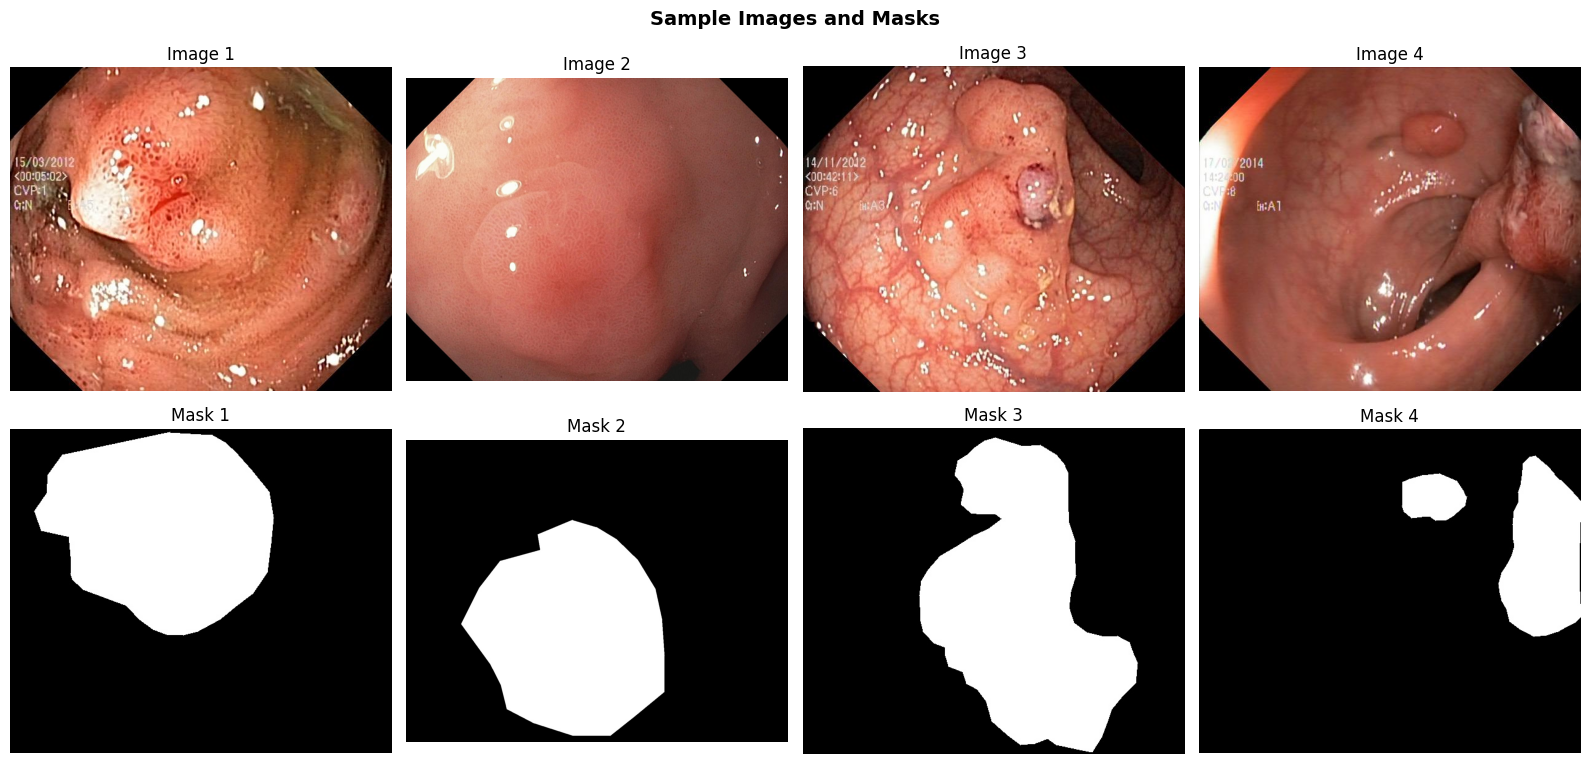

In [6]:
# ============================================================
# CELL 2.2 — Sample visualisation
# ============================================================
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
fig.suptitle('Sample Images and Masks', fontsize=14, fontweight='bold')
imgs_vis = sorted((KVASIR_DIR/'images').glob('*.jpg'))[:4]
for col, p in enumerate(imgs_vis):
    mp = KVASIR_DIR/'masks'/p.name
    axes[0,col].imshow(cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB))
    axes[0,col].set_title(f'Image {col+1}'); axes[0,col].axis('off')
    axes[1,col].imshow(cv2.cvtColor(cv2.imread(str(mp)), cv2.COLOR_BGR2RGB), cmap='hot')
    axes[1,col].set_title(f'Mask {col+1}'); axes[1,col].axis('off')
plt.tight_layout()
plt.savefig(OUTPUT_DIR/'sample_dataset.png', dpi=120, bbox_inches='tight')
# Also save to /kaggle/working root for the Output tab
shutil.copy(OUTPUT_DIR/'sample_dataset.png', WORKING_DIR/'sample_dataset.png')
plt.show()

## SECTION 3 — Preprocessing & Annotation

In [7]:
# ============================================================
# CELL 3.1 — Mask → bounding box helpers
# ============================================================

def mask_to_yolo_bbox(mask_path, img_w, img_h):
    """Convert binary segmentation mask to YOLO normalised bbox.
    Returns (class_id, x_center, y_center, width, height) all in [0,1]."""
    mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)
    if mask is None: return None
    mask = cv2.resize(mask, (img_w, img_h), interpolation=cv2.INTER_NEAREST)
    _, binary = cv2.threshold(mask, 127, 255, cv2.THRESH_BINARY)
    cnts, _ = cv2.findContours(binary, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not cnts: return None
    c = max(cnts, key=cv2.contourArea)
    if cv2.contourArea(c) < 100: return None
    x, y, w, h = cv2.boundingRect(c)
    return (0, (x+w/2)/img_w, (y+h/2)/img_h, w/img_w, h/img_h)

def mask_to_abs_bbox(mask_path, img_w, img_h):
    """Convert binary mask to absolute pixel bbox [x1, y1, x2, y2].
    Used by Faster R-CNN which expects pixel coordinates."""
    mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)
    if mask is None: return None
    mask = cv2.resize(mask, (img_w, img_h), interpolation=cv2.INTER_NEAREST)
    _, binary = cv2.threshold(mask, 127, 255, cv2.THRESH_BINARY)
    cnts, _ = cv2.findContours(binary, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not cnts: return None
    c = max(cnts, key=cv2.contourArea)
    if cv2.contourArea(c) < 100: return None
    x, y, w, h = cv2.boundingRect(c)
    return [float(x), float(y), float(x+w), float(y+h)]

def load_all_samples():
    samples = []
    for p in sorted((KVASIR_DIR/'images').glob('*.jpg')):
        mp = KVASIR_DIR/'masks'/p.name
        if mp.exists(): samples.append({'img':p,'mask':mp,'source':'kvasir'})
    print(f'  Kvasir-SEG   : {len([s for s in samples if s["source"]=="kvasir"])} samples')

    img_d = msk_d = None
    for d in ['images','Original','PNG','frames']:
        if (CVC_DIR/d).exists(): img_d = CVC_DIR/d; break
    for d in ['masks','Ground Truth','GT','ground_truth']:
        if (CVC_DIR/d).exists(): msk_d = CVC_DIR/d; break
    if img_d and msk_d:
        before = len(samples)
        for p in sorted(list(img_d.glob('*.tif'))+list(img_d.glob('*.png'))):
            for ext in ['.tif','.png','.jpg','.bmp']:
                mp = msk_d/(p.stem+ext)
                if mp.exists(): samples.append({'img':p,'mask':mp,'source':'cvc'}); break
        print(f'  CVC-ClinicDB : {len(samples)-before} samples')

    print(f'  Total        : {len(samples)} samples')
    return samples

print('Loading samples...')
ALL_SAMPLES = load_all_samples()

Loading samples...
  Kvasir-SEG   : 1000 samples
  CVC-ClinicDB : 612 samples
  Total        : 1612 samples


In [8]:
# ============================================================
# CELL 3.2 — Build YOLO + FRCNN datasets
# OPT: parallel processing, images resized to 416px
# CHECKPOINT: skips if already done
# ============================================================

if is_done('dataset_build'):
    print('✓ Dataset build already done — skipping.')
    YAML_PATH = get_val('dataset_build', 'yaml_path')
    yolo_base = Path(get_val('dataset_build', 'yolo_base'))
else:
    def split_samples(samples, train_r=0.70, val_r=0.15, seed=42):
        by_src = defaultdict(list)
        for s in samples: by_src[s['source']].append(s)
        train, val, test = [], [], []
        rng = random.Random(seed)
        for src_s in by_src.values():
            rng.shuffle(src_s); n=len(src_s)
            t1=int(n*train_r); t2=int(n*(train_r+val_r))
            train+=src_s[:t1]; val+=src_s[t1:t2]; test+=src_s[t2:]
        return train, val, test

    def process_sample(args):
        s, split_name, yb, frcnn_img_out = args
        img = cv2.imread(str(s['img']))
        if img is None: return None, None
        img_r = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
        stem  = f"{s['source']}_{s['img'].stem}"

        box_y = mask_to_yolo_bbox(s['mask'], IMG_SIZE, IMG_SIZE)
        if box_y:
            cv2.imwrite(str(yb/split_name/'images'/f'{stem}.jpg'), img_r,
                        [cv2.IMWRITE_JPEG_QUALITY, 92])
            cls,xc,yc,w,h = box_y
            (yb/split_name/'labels'/f'{stem}.txt').write_text(
                f'{cls} {xc:.6f} {yc:.6f} {w:.6f} {h:.6f}\n')

        box_a = mask_to_abs_bbox(s['mask'], IMG_SIZE, IMG_SIZE)
        rec = None
        if box_a:
            op = frcnn_img_out/f'{stem}.jpg'
            cv2.imwrite(str(op), img_r, [cv2.IMWRITE_JPEG_QUALITY, 92])
            rec = {'image_path':str(op),'boxes':[box_a],'labels':[1]}
        return box_y, rec

    def build_split(samples, split_name, yb, frcnn_recs):
        for d in [yb/split_name/'images', yb/split_name/'labels',
                  DATASET_DIR/'frcnn'/split_name/'images']:
            d.mkdir(parents=True, exist_ok=True)
        frcnn_img_out = DATASET_DIR/'frcnn'/split_name/'images'
        args = [(s, split_name, yb, frcnn_img_out) for s in samples]
        with ThreadPoolExecutor(max_workers=NUM_WORKERS) as ex:
            for _, rec in tqdm(ex.map(process_sample, args),
                               total=len(args), desc=f'  {split_name}'):
                if rec: frcnn_recs.append(rec)

    print(f'Building splits at {IMG_SIZE}px...')
    train_s, val_s, test_s = split_samples(ALL_SAMPLES)
    print(f'  train={len(train_s)}  val={len(val_s)}  test={len(test_s)}')

    yolo_base = DATASET_DIR/'yolo'
    frcnn_records = {'train':[],'val':[],'test':[]}
    for name, samp in [('train',train_s),('val',val_s),('test',test_s)]:
        build_split(samp, name, yolo_base, frcnn_records[name])

    yaml_path = yolo_base/'dataset.yaml'
    yaml_path.write_text(
        f'path: {yolo_base.absolute()}\n'
        f'train: train/images\nval: val/images\ntest: test/images\n'
        f'nc: 1\nnames: ["polyp"]\n'
    )

    for name, recs in frcnn_records.items():
        p = DATASET_DIR/'frcnn'/f'{name}_annotations.json'
        with open(p,'w') as f: json.dump(recs, f)
        print(f'  FRCNN {name}: {len(recs)} records')

    YAML_PATH = str(yaml_path)
    save_checkpoint('dataset_build', yaml_path=YAML_PATH, yolo_base=str(yolo_base))
    print('✓ Dataset ready.')

Building splits at 416px...
  train=1128  val=242  test=242


  test: 100%|██████████| 242/242 [00:04<00:00, 49.06it/s] 

  FRCNN train: 1128 records
  FRCNN val: 242 records
  FRCNN test: 242 records
  [✓ checkpoint saved: dataset_build]
✓ Dataset ready.


## SECTION 4 — YOLOv8n Training

In [9]:
# ============================================================
# CELL 4.1 — YOLOv8n 3-Fold Cross-Validation
# OPT: nano model, 416px, 40 epochs, patience=10, batch=8
# OPT: half=True (FP16), cache='disk'
# CHECKPOINT: per-fold save, resumes from last completed fold
# ============================================================

def collect_yolo_samples():
    out = []
    for split in ['train','val']:
        img_d = yolo_base/split/'images'
        lbl_d = yolo_base/split/'labels'
        for ip in sorted(img_d.glob('*.jpg')):
            lp = lbl_d/(ip.stem+'.txt')
            if lp.exists(): out.append({'img':ip,'lbl':lp})
    return out

def write_fold_yaml(fold_dir, tr, va):
    fold_dir.mkdir(parents=True, exist_ok=True)
    tr_txt = fold_dir/'train.txt'; va_txt = fold_dir/'val.txt'
    tr_txt.write_text('\n'.join(str(s['img']) for s in tr))
    va_txt.write_text('\n'.join(str(s['img']) for s in va))
    y = fold_dir/'fold.yaml'
    y.write_text(f'train: {tr_txt}\nval: {va_txt}\nnc: 1\nnames: [polyp]\n')
    return str(y)


if is_done('yolo_cv'):
    print('✓ YOLOv8 CV already done — skipping.')
    YOLO_CV_RESULTS = get_val('yolo_cv', 'fold_results')
else:
    cv_samp  = collect_yolo_samples()
    kf       = KFold(n_splits=K_FOLDS, shuffle=True, random_state=SEED)
    cv_dir   = RUNS_DIR/'yolo_cv'

    raw      = load_checkpoint_raw()
    fold_res = raw.get('yolo_cv_partial',{}).get('fold_results',[])
    done_f   = {r['fold'] for r in fold_res}

    print(f'YOLOv8n {K_FOLDS}-Fold CV | {len(cv_samp)} samples | done: {sorted(done_f)}')

    for fi, (tri, vai) in enumerate(kf.split(cv_samp)):
        fn = fi + 1
        if fn in done_f:
            print(f'  Fold {fn} — already done, skipping.'); continue

        print(f'\n── Fold {fn}/{K_FOLDS} ──')
        tr_s = [cv_samp[i] for i in tri]
        va_s = [cv_samp[i] for i in vai]
        fy   = write_fold_yaml(cv_dir/f'fold_{fn}_data', tr_s, va_s)

        model = YOLO('yolov8n.pt')
        res = model.train(
            data=fy, epochs=YOLO_EPOCHS, imgsz=IMG_SIZE, batch=BATCH_YOLO,
            project=str(cv_dir), name=f'fold_{fn}',
            patience=10, optimizer='AdamW', lr0=0.001, lrf=0.01,
            momentum=0.937, weight_decay=0.0005,
            augment=True, flipud=0.3, fliplr=0.5,
            mosaic=1.0, mixup=0.1, degrees=10.0,
            hsv_h=0.015, hsv_s=0.4, hsv_v=0.4,
            half=True,       # FP16 — halves VRAM
            cache='disk',    # disk cache — cheaper than RAM
            exist_ok=True, verbose=False,
            device=0 if torch.cuda.is_available() else 'cpu',
        )

        m = res.results_dict
        fm = {
            'fold'     : fn,
            'precision': float(m.get('metrics/precision(B)', 0)),
            'recall'   : float(m.get('metrics/recall(B)', 0)),
            'mAP50'    : float(m.get('metrics/mAP50(B)', 0)),
            'mAP50-95' : float(m.get('metrics/mAP50-95(B)', 0)),
            'weights'  : str(cv_dir/f'fold_{fn}'/'weights'/'best.pt'),
        }
        fold_res.append(fm)
        print(f'  Fold {fn} → mAP50:{fm["mAP50"]:.4f}  P:{fm["precision"]:.4f}  R:{fm["recall"]:.4f}')

        # Save partial checkpoint after each fold
        raw = load_checkpoint_raw()
        raw['yolo_cv_partial'] = {'fold_results': fold_res}
        with open(CKPT_FILE,'w') as f: json.dump(raw, f, indent=2)
        print(f'  [✓ fold {fn} saved to checkpoint]')

        del model, res; torch.cuda.empty_cache()

    print('\n=== YOLOv8 CV Summary ===')
    for met in ['mAP50','mAP50-95','precision','recall']:
        vs = [r[met] for r in fold_res]
        print(f'  {met:12s}: {np.mean(vs):.4f} ± {np.std(vs):.4f}')

    YOLO_CV_RESULTS = fold_res
    save_checkpoint('yolo_cv', fold_results=fold_res)

YOLOv8n 3-Fold CV | 1370 samples | done: []

── Fold 1/3 ──
Ultralytics 8.4.41 🚀 Python-3.12.12 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=True, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=disk, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/polyp_project/runs/yolo_cv/fold_1_data/fold.yaml, degrees=10.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=40, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.3, format=torchscript, fraction=1.0, freeze=None, half=True, hsv_h=0.015, hsv_s=0.4, hsv_v=0.4, imgsz=416, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.1, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=fold_1, nbs=6

In [10]:
# ============================================================
# CELL 4.2 — Train final YOLOv8n on full train+val
# KAGGLE: weights saved to /kaggle/working/ (persists)
# CHECKPOINT: skips if done; restores weights if local copy missing
# ============================================================

YOLO_PERSIST = str(WORKING_DIR/'yolov8n_best.pt')
YOLO_LOCAL   = str(RUNS_DIR/'yolo_final'/'polyp_detector'/'weights'/'best.pt')

if is_done('yolo_final'):
    print('✓ Final YOLOv8 done — skipping.')
    YOLO_WEIGHTS = get_val('yolo_final','weights_path')
    if YOLO_WEIGHTS and not Path(YOLO_WEIGHTS).exists() and Path(YOLO_PERSIST).exists():
        Path(YOLO_LOCAL).parent.mkdir(parents=True, exist_ok=True)
        shutil.copy(YOLO_PERSIST, YOLO_LOCAL); YOLO_WEIGHTS = YOLO_LOCAL
        print(f'  Restored from working dir.')
    print(f'  Weights: {YOLO_WEIGHTS}')
else:
    print('Training final YOLOv8n...')
    m = YOLO('yolov8n.pt')
    m.train(
        data=YAML_PATH, epochs=YOLO_EPOCHS, imgsz=IMG_SIZE, batch=BATCH_YOLO,
        project=str(RUNS_DIR/'yolo_final'), name='polyp_detector',
        patience=10, optimizer='AdamW', lr0=0.001, lrf=0.01,
        augment=True, flipud=0.3, fliplr=0.5,
        mosaic=1.0, mixup=0.1, degrees=10.0,
        half=True, cache='disk',
        exist_ok=True, verbose=True,
        device=0 if torch.cuda.is_available() else 'cpu',
    )
    YOLO_WEIGHTS = YOLO_LOCAL
    shutil.copy(YOLO_WEIGHTS, YOLO_PERSIST)  # persist to /kaggle/working/
    save_checkpoint('yolo_final', weights_path=YOLO_WEIGHTS)
    print(f'✓ Weights: {YOLO_WEIGHTS}')
    del m; torch.cuda.empty_cache()

Training final YOLOv8n...
Ultralytics 8.4.41 🚀 Python-3.12.12 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=True, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=disk, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/polyp_project/dataset/yolo/dataset.yaml, degrees=10.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=40, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.3, format=torchscript, fraction=1.0, freeze=None, half=True, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=416, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.1, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=polyp_detector, nbs=64, nms=False, opset=None, optimize=

## SECTION 5 — Faster R-CNN (ResNet50-FPN) Training

In [11]:
# ============================================================
# CELL 5.1 — FRCNN Dataset, model, loader, evaluate helpers
# ResNet50-FPN backbone kept exactly as in the paper
# OPT: pin_memory, persistent_workers, prefetch_factor
# ============================================================

class PolypFRCNNDataset(Dataset):
    def __init__(self, records, img_size=416, augment=False):
        self.records=records; self.img_size=img_size
        self.augment=augment; self.to_tensor=transforms.ToTensor()

    def __len__(self): return len(self.records)

    def _augment(self, img, boxes):
        h,w=img.shape[:2]
        if random.random()>0.5:    # horizontal flip
            img=cv2.flip(img,1); boxes=[[w-b[2],b[1],w-b[0],b[3]] for b in boxes]
        if random.random()>0.5:    # vertical flip
            img=cv2.flip(img,0); boxes=[[b[0],h-b[3],b[2],h-b[1]] for b in boxes]
        if random.random()>0.5:    # brightness jitter
            img=cv2.convertScaleAbs(img,alpha=random.uniform(0.8,1.2),beta=random.randint(-15,15))
        return img, boxes

    def __getitem__(self, idx):
        rec=self.records[idx]
        img=cv2.imread(rec['image_path'])
        img=cv2.resize(img,(self.img_size,self.img_size)) if img is not None \
            else np.zeros((self.img_size,self.img_size,3),dtype=np.uint8)
        img=cv2.cvtColor(img,cv2.COLOR_BGR2RGB)
        boxes=[list(b) for b in rec['boxes']]; labels=list(rec['labels'])
        if self.augment: img,boxes=self._augment(img,boxes)
        vb,vl=[],[]
        for box,lbl in zip(boxes,labels):
            x1=max(0.,float(box[0])); y1=max(0.,float(box[1]))
            x2=min(float(self.img_size),float(box[2]))
            y2=min(float(self.img_size),float(box[3]))
            if x2>x1+1 and y2>y1+1: vb.append([x1,y1,x2,y2]); vl.append(lbl)
        if not vb: vb,vl=[[0.,0.,10.,10.]],[1]
        return self.to_tensor(img), {
            'boxes':torch.tensor(vb,dtype=torch.float32),
            'labels':torch.tensor(vl,dtype=torch.int64)}


def make_loader(dataset, batch_size, shuffle):
    return DataLoader(
        dataset, batch_size=batch_size, shuffle=shuffle,
        collate_fn=lambda x: tuple(zip(*x)),
        num_workers=NUM_WORKERS,
        pin_memory=torch.cuda.is_available(),
        persistent_workers=(NUM_WORKERS>0),
        prefetch_factor=2 if NUM_WORKERS>0 else None,
    )


def build_frcnn_model(num_classes=2):
    """Faster R-CNN with ResNet50-FPN backbone (same as paper).
    Pretrained on COCO. Head replaced for 2 classes: background + polyp."""
    model = fasterrcnn_resnet50_fpn(weights=FasterRCNN_ResNet50_FPN_Weights.DEFAULT)
    in_f = model.roi_heads.box_predictor.cls_score.in_features
    model.roi_heads.box_predictor = FastRCNNPredictor(in_f, num_classes)
    return model


@torch.no_grad()
def evaluate_frcnn(model, loader, iou_thr=0.5, conf_thr=0.5):
    model.eval(); tp=fp=fn=0
    for imgs, targets in loader:
        imgs=[i.to(DEVICE) for i in imgs]; outs=model(imgs)
        for out,tgt in zip(outs,targets):
            pb=out['boxes'][out['scores']>=conf_thr].cpu(); gb=tgt['boxes'].cpu()
            if len(gb)==0 and len(pb)==0: continue
            if len(gb)==0: fp+=len(pb); continue
            if len(pb)==0: fn+=len(gb); continue
            iou=box_iou(pb,gb); matched=set()
            for pi in range(len(pb)):
                best_iou,best_gi=iou[pi].max(0)
                if best_iou>=iou_thr and best_gi.item() not in matched:
                    tp+=1; matched.add(best_gi.item())
                else: fp+=1
            fn+=len(gb)-len(matched)
    p=tp/(tp+fp+1e-8); r=tp/(tp+fn+1e-8)
    return {'precision':p,'recall':r,'f1':2*p*r/(p+r+1e-8),'mAP50':p*r}


print('Faster R-CNN (ResNet50-FPN) helpers defined.')

Faster R-CNN (ResNet50-FPN) helpers defined.


In [12]:
# ============================================================
# CELL 5.2 — FRCNN 3-Fold CV
# OPT: batch=2 + GRAD_ACCUM=4 → effective batch=8 (no OOM)
# OPT: AMP autocast throughout
# OPT: backbone frozen 5 epochs (warmup), then unfrozen
# OPT: evaluate only every 5 epochs
# CHECKPOINT: per-fold save, resumes from last done fold
# ============================================================

all_frcnn = []
for sp in ['train','val']:
    fp = DATASET_DIR/'frcnn'/f'{sp}_annotations.json'
    if fp.exists():
        with open(fp) as f: all_frcnn += json.load(f)
print(f'FRCNN CV records: {len(all_frcnn)}')

if is_done('frcnn_cv'):
    print('✓ FRCNN CV already done — skipping.')
    FRCNN_CV_RESULTS = get_val('frcnn_cv','fold_results')
else:
    kf_f     = KFold(n_splits=K_FOLDS, shuffle=True, random_state=SEED)
    frcnn_dir= RUNS_DIR/'frcnn_cv'
    frcnn_dir.mkdir(parents=True, exist_ok=True)

    raw    = load_checkpoint_raw()
    f_res  = raw.get('frcnn_cv_partial',{}).get('fold_results',[])
    done_f = {r['fold'] for r in f_res}
    scaler = GradScaler(enabled=torch.cuda.is_available())

    print(f'FRCNN {K_FOLDS}-Fold CV | done: {sorted(done_f)}')

    for fi, (tri, vai) in enumerate(kf_f.split(all_frcnn)):
        fn = fi+1
        if fn in done_f:
            print(f'  Fold {fn} — already done, skipping.'); continue

        print(f'\n── Fold {fn}/{K_FOLDS} ──')
        tr_dl = make_loader(
            PolypFRCNNDataset([all_frcnn[i] for i in tri], IMG_SIZE, augment=True),
            BATCH_FRCNN, shuffle=True)
        va_dl = make_loader(
            PolypFRCNNDataset([all_frcnn[i] for i in vai], IMG_SIZE, augment=False),
            BATCH_FRCNN, shuffle=False)

        model = build_frcnn_model().to(DEVICE)
        for p in model.backbone.parameters(): p.requires_grad = False
        WARMUP = 5
        opt = torch.optim.AdamW(
            filter(lambda p: p.requires_grad, model.parameters()),
            lr=5e-4, weight_decay=5e-4)
        sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=FRCNN_EPOCHS)
        best_map=0.0; wts=frcnn_dir/f'fold_{fn}_best.pt'

        for epoch in range(FRCNN_EPOCHS):
            if epoch == WARMUP:
                for p in model.backbone.parameters(): p.requires_grad = True
                opt = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=5e-4)
                sch = torch.optim.lr_scheduler.CosineAnnealingLR(
                    opt, T_max=FRCNN_EPOCHS-WARMUP)

            model.train(); ep_loss=0.0; opt.zero_grad()
            for step,(imgs,tgts) in enumerate(tr_dl):
                imgs=[i.to(DEVICE) for i in imgs]
                tgts=[{k:v.to(DEVICE) for k,v in t.items()} for t in tgts]
                with autocast(enabled=torch.cuda.is_available()):
                    loss = sum(model(imgs,tgts).values()) / GRAD_ACCUM
                scaler.scale(loss).backward()
                if (step+1)%GRAD_ACCUM==0 or (step+1)==len(tr_dl):
                    scaler.unscale_(opt)
                    torch.nn.utils.clip_grad_norm_(model.parameters(),1.0)
                    scaler.step(opt); scaler.update(); opt.zero_grad()
                ep_loss += loss.item()*GRAD_ACCUM
            sch.step()

            if (epoch+1)%5==0 or epoch==FRCNN_EPOCHS-1:
                mm = evaluate_frcnn(model, va_dl)
                print(f'  Ep {epoch+1:2d} | Loss:{ep_loss/len(tr_dl):.3f} | '
                      f'mAP50:{mm["mAP50"]:.3f} P:{mm["precision"]:.3f} R:{mm["recall"]:.3f}')
                if mm['mAP50']>best_map:
                    best_map=mm['mAP50']; torch.save(model.state_dict(),wts)

        fm = evaluate_frcnn(model, va_dl)
        f_res.append({'fold':fn,**fm,'weights':str(wts)})
        print(f'  ✓ Fold {fn} best mAP50: {best_map:.4f}')

        raw = load_checkpoint_raw()
        raw['frcnn_cv_partial'] = {'fold_results': f_res}
        with open(CKPT_FILE,'w') as f: json.dump(raw, f, indent=2)
        print(f'  [✓ fold {fn} saved to checkpoint]')

        del model, tr_dl, va_dl; torch.cuda.empty_cache()

    print('\n=== FRCNN CV Summary ===')
    for met in ['mAP50','precision','recall','f1']:
        vs=[r[met] for r in f_res]
        print(f'  {met:12s}: {np.mean(vs):.4f} ± {np.std(vs):.4f}')

    FRCNN_CV_RESULTS = f_res
    save_checkpoint('frcnn_cv', fold_results=f_res)

FRCNN CV records: 1370
FRCNN 3-Fold CV | done: []

── Fold 1/3 ──
Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth


100%|██████████| 160M/160M [00:00<00:00, 214MB/s]


  Ep  5 | Loss:0.118 | mAP50:0.382 P:0.428 R:0.891
  Ep 10 | Loss:0.076 | mAP50:0.569 P:0.605 R:0.941
  Ep 15 | Loss:0.043 | mAP50:0.746 P:0.784 R:0.952
  ✓ Fold 1 best mAP50: 0.7461
  [✓ fold 1 saved to checkpoint]

── Fold 2/3 ──
  Ep  5 | Loss:0.122 | mAP50:0.362 P:0.406 R:0.893
  Ep 10 | Loss:0.078 | mAP50:0.500 P:0.532 R:0.941
  Ep 15 | Loss:0.044 | mAP50:0.721 P:0.758 R:0.952
  ✓ Fold 2 best mAP50: 0.7214
  [✓ fold 2 saved to checkpoint]

── Fold 3/3 ──
  Ep  5 | Loss:0.124 | mAP50:0.454 P:0.520 R:0.873
  Ep 10 | Loss:0.078 | mAP50:0.561 P:0.596 R:0.941
  Ep 15 | Loss:0.046 | mAP50:0.741 P:0.773 R:0.958
  ✓ Fold 3 best mAP50: 0.7412
  [✓ fold 3 saved to checkpoint]

=== FRCNN CV Summary ===
  mAP50       : 0.7362 ± 0.0107
  precision   : 0.7717 ± 0.0107
  recall      : 0.9540 ± 0.0031
  f1          : 0.8532 ± 0.0068
  [✓ checkpoint saved: frcnn_cv]


In [13]:
# ============================================================
# CELL 5.3 — Train final FRCNN (ResNet50-FPN)
# OPT: batch=2, grad_accum=4, AMP, 15 epochs
# KAGGLE: weights backed up to /kaggle/working/ every 5 epochs
# CHECKPOINT: skips if done
# ============================================================

FRCNN_PERSIST = str(WORKING_DIR/'frcnn_resnet50_best.pt')
FRCNN_LOCAL   = str(RUNS_DIR/'frcnn_final_best.pt')

if is_done('frcnn_final'):
    print('✓ Final FRCNN done — skipping.')
    FRCNN_WEIGHTS = get_val('frcnn_final','weights_path')
    if FRCNN_WEIGHTS and not Path(FRCNN_WEIGHTS).exists() and Path(FRCNN_PERSIST).exists():
        shutil.copy(FRCNN_PERSIST, FRCNN_LOCAL); FRCNN_WEIGHTS = FRCNN_LOCAL
        print('  Restored from working dir.')
    print(f'  Weights: {FRCNN_WEIGHTS}')
else:
    full_recs = []
    for sp in ['train','val']:
        fp = DATASET_DIR/'frcnn'/f'{sp}_annotations.json'
        if fp.exists():
            with open(fp) as f: full_recs += json.load(f)

    print(f'Training final FRCNN (ResNet50-FPN) on {len(full_recs)} samples...')
    dl = make_loader(PolypFRCNNDataset(full_recs,IMG_SIZE,augment=True),BATCH_FRCNN,True)

    model = build_frcnn_model().to(DEVICE)
    for p in model.backbone.parameters(): p.requires_grad=False
    WARMUP=5
    opt = torch.optim.AdamW(
        filter(lambda p: p.requires_grad, model.parameters()),lr=5e-4,weight_decay=5e-4)
    sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=FRCNN_EPOCHS)
    scaler = GradScaler(enabled=torch.cuda.is_available())
    FRCNN_WEIGHTS = FRCNN_LOCAL; best_loss=float('inf')

    for epoch in range(FRCNN_EPOCHS):
        if epoch==WARMUP:
            for p in model.backbone.parameters(): p.requires_grad=True
            opt = torch.optim.AdamW(model.parameters(),lr=1e-4,weight_decay=5e-4)
            sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt,T_max=FRCNN_EPOCHS-WARMUP)

        model.train(); ep_loss=0.0; opt.zero_grad()
        for step,(imgs,tgts) in enumerate(dl):
            imgs=[i.to(DEVICE) for i in imgs]
            tgts=[{k:v.to(DEVICE) for k,v in t.items()} for t in tgts]
            with autocast(enabled=torch.cuda.is_available()):
                loss=sum(model(imgs,tgts).values())/GRAD_ACCUM
            scaler.scale(loss).backward()
            if (step+1)%GRAD_ACCUM==0 or (step+1)==len(dl):
                scaler.unscale_(opt)
                torch.nn.utils.clip_grad_norm_(model.parameters(),1.0)
                scaler.step(opt); scaler.update(); opt.zero_grad()
            ep_loss+=loss.item()*GRAD_ACCUM
        sch.step()
        avg=ep_loss/len(dl)
        if avg<best_loss: best_loss=avg; torch.save(model.state_dict(),FRCNN_WEIGHTS)
        if (epoch+1)%5==0:
            print(f'  Epoch {epoch+1}/{FRCNN_EPOCHS} | Loss:{avg:.4f}')
            shutil.copy(FRCNN_WEIGHTS, FRCNN_PERSIST)
            print(f'  [✓ epoch {epoch+1} weights saved to /kaggle/working/]')

    save_checkpoint('frcnn_final', weights_path=FRCNN_WEIGHTS)
    shutil.copy(FRCNN_WEIGHTS, FRCNN_PERSIST)
    print(f'✓ Final FRCNN weights: {FRCNN_WEIGHTS}')
    del model, dl; torch.cuda.empty_cache()

Training final FRCNN (ResNet50-FPN) on 1370 samples...
  Epoch 5/15 | Loss:0.1143
  [✓ epoch 5 weights saved to /kaggle/working/]
  Epoch 10/15 | Loss:0.0694
  [✓ epoch 10 weights saved to /kaggle/working/]
  Epoch 15/15 | Loss:0.0391
  [✓ epoch 15 weights saved to /kaggle/working/]
  [✓ checkpoint saved: frcnn_final]
✓ Final FRCNN weights: /kaggle/working/polyp_project/runs/frcnn_final_best.pt


## SECTION 6 — Ensemble (WBF) + ByteTrack + Inference

In [14]:
# ============================================================
# CELL 6.1 — EnsembleDetector (YOLOv8n + FRCNN + WBF)
# OPT: AMP autocast on FRCNN inference
# ============================================================

class EnsembleDetector:
    def __init__(self, yolo_weights, frcnn_weights,
                 yolo_conf=0.35, frcnn_conf=0.40,
                 wbf_iou=0.55, wbf_skip=0.25,
                 yolo_w=1.0, frcnn_w=1.2):
        self.yolo_conf=yolo_conf; self.frcnn_conf=frcnn_conf
        self.wbf_iou=wbf_iou; self.wbf_skip=wbf_skip
        self.yolo_w=yolo_w; self.frcnn_w=frcnn_w
        self.tf=transforms.ToTensor()
        print('Loading YOLOv8n...'); self.yolo=YOLO(yolo_weights)
        print('Loading Faster R-CNN (ResNet50-FPN)...')
        self.frcnn=build_frcnn_model().to(DEVICE)
        self.frcnn.load_state_dict(torch.load(frcnn_weights,map_location=DEVICE))
        self.frcnn.eval()
        print('✓ Both models loaded')

    @torch.no_grad()
    def predict(self, frame_bgr):
        h,w=frame_bgr.shape[:2]
        boxes_l,scores_l,labels_l,wts=[],[],[],[]

        res=self.yolo(frame_bgr,imgsz=IMG_SIZE,conf=self.yolo_conf,verbose=False,device=DEVICE)
        yb,ys,yl=[],[],[]
        for r in res:
            for box in r.boxes:
                x1,y1,x2,y2=box.xyxy[0].tolist()
                yb.append([x1/w,y1/h,x2/w,y2/h])
                ys.append(float(box.conf[0])); yl.append(int(box.cls[0]))
        if yb: boxes_l.append(yb); scores_l.append(ys); labels_l.append(yl); wts.append(self.yolo_w)

        rgb=cv2.cvtColor(frame_bgr,cv2.COLOR_BGR2RGB)
        t=self.tf(rgb).unsqueeze(0).to(DEVICE)
        with autocast(enabled=torch.cuda.is_available()): out=self.frcnn(t)[0]
        fb,fs,fl=[],[],[]
        for box,score,label in zip(out['boxes'],out['scores'],out['labels']):
            if score<self.frcnn_conf: continue
            x1,y1,x2,y2=box.tolist()
            fb.append([x1/w,y1/h,x2/w,y2/h]); fs.append(float(score)); fl.append(int(label)-1)
        if fb: boxes_l.append(fb); scores_l.append(fs); labels_l.append(fl); wts.append(self.frcnn_w)

        if not boxes_l: return []
        mb,ms,ml=weighted_boxes_fusion(boxes_l,scores_l,labels_l,
                                       weights=wts,iou_thr=self.wbf_iou,skip_box_thr=self.wbf_skip)
        return [{'box':[b[0]*w,b[1]*h,b[2]*w,b[3]*h],'score':float(s),'class_id':int(l)}
                for b,s,l in zip(mb,ms,ml)]


class TrackedDetector:
    def __init__(self, detector, min_hits=3):
        self.detector=detector; self.tracker=sv.ByteTrack()
        self.min_hits=min_hits; self.track_hits={}

    def predict(self, frame):
        raw=self.detector.predict(frame)
        if not raw: self.track_hits.clear(); return []
        boxes=np.array([[d['box'][0],d['box'][1],d['box'][2],d['box'][3]] for d in raw])
        scores=np.array([d['score'] for d in raw])
        labels=np.array([d['class_id'] for d in raw])
        tracked=self.tracker.update_with_detections(
            sv.Detections(xyxy=boxes,confidence=scores,class_id=labels))
        cur=set(tracked.tracker_id) if tracked.tracker_id is not None else set()
        for tid in list(self.track_hits):
            if tid not in cur: del self.track_hits[tid]
        for tid in cur: self.track_hits[tid]=self.track_hits.get(tid,0)+1
        out=[]
        if tracked.tracker_id is not None:
            for i,tid in enumerate(tracked.tracker_id):
                if self.track_hits.get(tid,0)>=self.min_hits:
                    out.append({
                        'box':tracked.xyxy[i].tolist(),
                        'score':float(tracked.confidence[i]) if tracked.confidence is not None else 0.5,
                        'class_id':int(tracked.class_id[i]) if tracked.class_id is not None else 0,
                        'track_id':int(tid)})
        return out


print('EnsembleDetector and TrackedDetector defined.')

EnsembleDetector and TrackedDetector defined.


In [15]:
# ============================================================
# CELL 6.2 — Video inference + demo video creation
# OPT: background writer thread
# KAGGLE: output saved to /kaggle/working/ for Output tab download
# ============================================================

def draw_detections(frame, dets, show_track=True):
    COLORS={0:(0,220,255),1:(80,220,80),2:(220,80,80)}
    NAMES={0:'polyp',1:'TA',2:'HP'}
    for d in dets:
        x1,y1,x2,y2=[int(v) for v in d['box']]
        c=COLORS.get(d.get('class_id',0),(0,220,255))
        lbl=f"{NAMES.get(d.get('class_id',0),'polyp')} {d['score']:.2f}"
        if show_track and d.get('track_id') is not None: lbl+=f" #{d['track_id']}"
        cv2.rectangle(frame,(x1,y1),(x2,y2),c,3)
        cl=min(18,(x2-x1)//5,(y2-y1)//5)
        for cx,cy,dx,dy in [(x1,y1,1,1),(x2,y1,-1,1),(x1,y2,1,-1),(x2,y2,-1,-1)]:
            cv2.line(frame,(cx,cy),(cx+dx*cl,cy),c,4)
            cv2.line(frame,(cx,cy),(cx,cy+dy*cl),c,4)
        (tw,th),_=cv2.getTextSize(lbl,cv2.FONT_HERSHEY_SIMPLEX,0.55,2)
        ty=max(y1-8,th+6)
        cv2.rectangle(frame,(x1,ty-th-4),(x1+tw+8,ty+2),c,-1)
        cv2.putText(frame,lbl,(x1+4,ty-2),cv2.FONT_HERSHEY_SIMPLEX,0.55,(20,20,20),2,cv2.LINE_AA)
    return frame

def draw_hud(frame,fps,n):
    h,w=frame.shape[:2]; ov=frame.copy()
    cv2.rectangle(ov,(0,0),(w,52),(12,18,28),-1); cv2.addWeighted(ov,0.8,frame,0.2,0,frame)
    cv2.putText(frame,f'FPS:{fps:5.1f}',(10,34),cv2.FONT_HERSHEY_SIMPLEX,0.75,(0,220,255),2,cv2.LINE_AA)
    cv2.putText(frame,'Ensemble+ByteTrack',(w//2-110,34),cv2.FONT_HERSHEY_SIMPLEX,0.55,(200,200,200),1,cv2.LINE_AA)
    if n>0: cv2.putText(frame,f'POLYPS:{n}',(w-150,34),cv2.FONT_HERSHEY_SIMPLEX,0.65,(60,255,180),2,cv2.LINE_AA)
    return frame

def _writer_fn(writer,q):
    while True:
        f=q.get()
        if f is None: break
        writer.write(f); q.task_done()

def run_inference(source, detector, out_path, use_track=True, max_frames=None):
    cap=cv2.VideoCapture(source)
    if not cap.isOpened(): print(f'Cannot open {source}'); return {}
    fps_in=cap.get(cv2.CAP_PROP_FPS) or 25
    fw=int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)); fh=int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    n_tot=int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    writer=cv2.VideoWriter(str(out_path),cv2.VideoWriter_fourcc(*'mp4v'),fps_in,(fw,fh))
    wq=queue.Queue(maxsize=8)
    wt=threading.Thread(target=_writer_fn,args=(writer,wq),daemon=True); wt.start()
    lats=[]; fidx=0; t0=time.time()
    with tqdm(total=min(n_tot,max_frames or n_tot),desc='Inference') as pb:
        while True:
            ok,frame=cap.read()
            if not ok or (max_frames and fidx>=max_frames): break
            t1=time.time(); dets=detector.predict(frame); lats.append((time.time()-t1)*1000)
            fps_avg=1000./np.mean(lats[-30:])
            frame=draw_detections(frame,dets,show_track=use_track)
            frame=draw_hud(frame,fps_avg,len(dets))
            wq.put(frame.copy()); fidx+=1
            pb.update(1); pb.set_postfix({'fps':f'{fps_avg:.1f}','dets':len(dets)})
    cap.release(); wq.put(None); wt.join(); writer.release()
    tt=time.time()-t0
    st={'frames':fidx,'time_s':tt,'avg_fps':fidx/tt,
        'avg_lat_ms':np.mean(lats),'p95_lat_ms':np.percentile(lats,95)}
    print(f'  ✓ {fidx} frames | FPS:{st["avg_fps"]:.1f} | Lat:{st["avg_lat_ms"]:.1f}ms')
    return st

def make_demo_video(img_dir, out, fps=10, dur=20):
    imgs=sorted(Path(img_dir).glob('*.jpg'))[:fps*dur]
    if not imgs: print('No test images'); return None
    h,w=cv2.imread(str(imgs[0])).shape[:2]
    wr=cv2.VideoWriter(str(out),cv2.VideoWriter_fourcc(*'mp4v'),fps,(w,h))
    fl=(imgs*((fps*dur//len(imgs))+1))[:fps*dur]
    for p in tqdm(fl,desc='Building demo'): wr.write(cv2.imread(str(p)))
    wr.release(); print(f'✓ Demo: {out}'); return str(out)


DEMO = str(OUTPUT_DIR/'demo.mp4')
IOUT = str(OUTPUT_DIR/'inference_result.mp4')

make_demo_video(DATASET_DIR/'yolo'/'test'/'images', DEMO)

detector = EnsembleDetector(YOLO_WEIGHTS, FRCNN_WEIGHTS)
tracked  = TrackedDetector(detector, min_hits=3)
stats    = run_inference(DEMO, tracked, IOUT, use_track=True, max_frames=200)

# Copy result to /kaggle/working/ for Output tab
shutil.copy(IOUT, WORKING_DIR/'inference_result.mp4')
print('\nStats:'); [print(f'  {k}: {v:.2f}') for k,v in stats.items()]

Building demo: 100%|██████████| 200/200 [00:00<00:00, 316.83it/s]


✓ Demo: /kaggle/working/polyp_project/outputs/demo.mp4
Loading YOLOv8n...
Loading Faster R-CNN (ResNet50-FPN)...
✓ Both models loaded


Inference: 100%|██████████| 200/200 [00:13<00:00, 14.97it/s, fps=16.0, dets=1]


  ✓ 200 frames | FPS:15.0 | Lat:63.8ms

Stats:
  frames: 200.00
  time_s: 13.36
  avg_fps: 14.97
  avg_lat_ms: 63.82
  p95_lat_ms: 64.03


[None, None, None, None, None]

## SECTION 7 — Evaluation

In [16]:
# ============================================================
# CELL 7.1 — YOLOv8 test evaluation (checkpoint)
# ============================================================
if is_done('yolo_eval'):
    print('✓ YOLOv8 eval done.'); yolo_test=get_val('yolo_eval','metrics')
else:
    em=YOLO(YOLO_WEIGHTS)
    ym=em.val(data=YAML_PATH,split='test',imgsz=IMG_SIZE,conf=0.35,iou=0.5,verbose=True,
              device=0 if torch.cuda.is_available() else 'cpu')
    yolo_test={'Model':'YOLOv8n','Precision':float(ym.box.mp),'Recall':float(ym.box.mr),
               'mAP50':float(ym.box.map50),'mAP50-95':float(ym.box.map),
               'F1':2*ym.box.mp*ym.box.mr/(ym.box.mp+ym.box.mr+1e-8)}
    save_checkpoint('yolo_eval',metrics=yolo_test)
print('\nYOLOv8n:')
for k,v in yolo_test.items():
    print(f'  {k:12s}: {v:.4f}' if isinstance(v,float) else f'  {k:12s}: {v}')

Ultralytics 8.4.41 🚀 Python-3.12.12 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,005,843 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1020.7±391.2 MB/s, size: 37.4 KB)
val: Scanning /kaggle/working/polyp_project/dataset/yolo/test/labels... 242 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 242/242 1.3Kit/s 0.2s
val: New cache created: /kaggle/working/polyp_project/dataset/yolo/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 16/16 7.1it/s 2.3s
                   all        242        242      0.895      0.917      0.897      0.708
Speed: 0.7ms preprocess, 3.8ms inference, 0.0ms loss, 0.9ms postprocess per image
Results saved to /kaggle/working/runs/detect/val
  [✓ checkpoint saved: yolo_eval]

YOLOv8n:
  Model       : YOLOv8n
  Precision   : 0.8952
  Recall      : 0.9174
  mAP50       : 0.8970
  mAP50-95    : 0.7079
  F1       

In [17]:
# ============================================================
# CELL 7.2 — FRCNN test evaluation (checkpoint)
# ============================================================
if is_done('frcnn_eval'):
    print('✓ FRCNN eval done.'); frcnn_test=get_val('frcnn_eval','metrics')
else:
    with open(DATASET_DIR/'frcnn'/'test_annotations.json') as f: test_recs=json.load(f)
    tdl=make_loader(PolypFRCNNDataset(test_recs,IMG_SIZE,augment=False),BATCH_FRCNN,False)
    ef=build_frcnn_model().to(DEVICE)
    ef.load_state_dict(torch.load(FRCNN_WEIGHTS,map_location=DEVICE))
    frcnn_test=evaluate_frcnn(ef,tdl)
    frcnn_test['Model']='Faster R-CNN ResNet50-FPN'; frcnn_test['mAP50-95']='N/A'
    save_checkpoint('frcnn_eval',metrics=frcnn_test)
print('\nFaster R-CNN (ResNet50-FPN):')
for k,v in frcnn_test.items():
    print(f'  {k:12s}: {v:.4f}' if isinstance(v,float) else f'  {k:12s}: {v}')

  [✓ checkpoint saved: frcnn_eval]

Faster R-CNN (ResNet50-FPN):
  precision   : 0.8076
  recall      : 0.9711
  f1          : 0.8818
  mAP50       : 0.7842
  Model       : Faster R-CNN ResNet50-FPN
  mAP50-95    : N/A


In [18]:
# ============================================================
# CELL 7.3 — Summary table + save to /kaggle/working/
# ============================================================
import pandas as pd

df=pd.DataFrame([
    {'Model':'YOLOv8n','P':yolo_test['Precision'],'R':yolo_test['Recall'],
     'F1':yolo_test['F1'],'mAP50':yolo_test['mAP50']},
    {'Model':'FRCNN-ResNet50','P':frcnn_test['precision'],'R':frcnn_test['recall'],
     'F1':frcnn_test['f1'],'mAP50':frcnn_test['mAP50']},
])
print('\n'+'='*60)
print('  FINAL RESULTS — Optimised Kaggle Edition')
print('='*60)
print(df.to_string(index=False, float_format='{:.4f}'.format))
print('='*60)

df.to_csv(OUTPUT_DIR/'evaluation_results.csv', index=False)
# Copy to /kaggle/working/ root so it appears in Output tab
shutil.copy(OUTPUT_DIR/'evaluation_results.csv', WORKING_DIR/'evaluation_results.csv')
print('\n✓ Results saved. Download from the Kaggle Output tab.')


  FINAL RESULTS — Optimised Kaggle Edition
         Model      P      R     F1  mAP50
       YOLOv8n 0.8952 0.9174 0.9061 0.8970
FRCNN-ResNet50 0.8076 0.9711 0.8818 0.7842

✓ Results saved. Download from the Kaggle Output tab.


## SECTION 8 — Status & Download

In [19]:
# ============================================================
# CELL 8.1 — Copy all outputs to /kaggle/working/ + show status
# On Kaggle: go to Output tab (right sidebar) to download files
# ============================================================

# Copy key files to /kaggle/working/ root
copy_jobs = [
    (YOLO_WEIGHTS,                    WORKING_DIR/'yolov8n_best.pt'),
    (FRCNN_WEIGHTS,                   WORKING_DIR/'frcnn_resnet50_best.pt'),
    (str(OUTPUT_DIR/'evaluation_results.csv'), WORKING_DIR/'evaluation_results.csv'),
    (str(OUTPUT_DIR/'sample_dataset.png'),     WORKING_DIR/'sample_dataset.png'),
    (str(OUTPUT_DIR/'inference_result.mp4'),   WORKING_DIR/'inference_result.mp4'),
]
print('Copying outputs to /kaggle/working/ ...')
for src, dst in copy_jobs:
    if Path(src).exists():
        shutil.copy(src, dst); print(f'  ✓ {dst.name}')

print('\n=== Files in /kaggle/working/ (visible in Output tab) ===')
for f in sorted(WORKING_DIR.glob('*')):
    if f.is_file():
        print(f'  {f.name:45s} {f.stat().st_size/1e6:.1f} MB')

print('\n=== Checkpoint Status ===')
ckpt = load_checkpoint_raw()
for s in ['dataset_extraction','dataset_build','yolo_cv','yolo_final',
          'frcnn_cv','frcnn_final','yolo_eval','frcnn_eval']:
    done=ckpt.get(s,{}).get('done',False)
    ts  =ckpt.get(s,{}).get('ts','-')
    print(f'  {"✓" if done else "○"}  {s:25s}  {ts}')

print('\n  reset_checkpoint("stage") — re-run one stage')
print('  reset_checkpoint()        — start completely fresh')

Copying outputs to /kaggle/working/ ...
  ✓ yolov8n_best.pt
  ✓ frcnn_resnet50_best.pt
  ✓ evaluation_results.csv
  ✓ sample_dataset.png
  ✓ inference_result.mp4

=== Files in /kaggle/working/ (visible in Output tab) ===
  __notebook__.ipynb                            4.7 MB
  evaluation_results.csv                        0.0 MB
  frcnn_resnet50_best.pt                        165.7 MB
  inference_result.mp4                          3.5 MB
  pipeline_checkpoint.json                      0.0 MB
  sample_dataset.png                            1.1 MB
  yolo26n.pt                                    5.5 MB
  yolov8n.pt                                    6.5 MB
  yolov8n_best.pt                               6.2 MB

=== Checkpoint Status ===
  ✓  dataset_extraction         2026-04-23 07:29:50
  ✓  dataset_build              2026-04-23 07:30:33
  ✓  yolo_cv                    2026-04-23 07:54:06
  ✓  yolo_final                 2026-04-23 08:02:04
  ✓  frcnn_cv                   2026-04-23 09:2

In [20]:
import shutil

# Compress the entire working directory
shutil.make_archive(
    base_name='/kaggle/working/polyp_project_outputs',
    format='zip',
    root_dir='/kaggle/working'
)

print("✅ ZIP file created: /kaggle/working/polyp_project_outputs.zip")

✅ ZIP file created: /kaggle/working/polyp_project_outputs.zip
